# FinSight Phase 1: development dataset EDA

This notebook regenerates the five aggregate figures using verified train/validation records only. All test candidates remain withheld. Read `docs/phase1-findings.md` and the three dataset cards for interpretations, licenses, and limitations. Install the optional EDA group and select the project Python kernel. No models or class thresholds are introduced.

In [1]:
from pathlib import Path

from finsight.config import Settings
from finsight.data.eda import FIGURE_NAMES, generate_eda

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), (
    "Start in the repository or notebooks directory"
)
data_dir = Settings.from_env().data_dir
if not data_dir.is_absolute():
    data_dir = ROOT / data_dir
summary = generate_eda(
    data_dir,
    ROOT / "configs/asset-revisions.json",
    ROOT / "configs/benchmark-freeze.json",
    ROOT / "reports",
)

## Scope and counting units

PhraseBank labels count sentences. SEntFiN labels count target annotations, while text lengths and target multiplicity count headlines once each. FiQA scores remain continuous; numeric signs and histogram intervals do not define classes. Agreement subsets overlap and are not independent samples. Word counts use whitespace splitting and are not tokenizer lengths.

In [2]:
print(summary["scope"])
for corpus, group in summary["corpora"].items():
    print(corpus, group["records"], "texts", group["partitions"])
print("Frozen benchmark digest:", summary["benchmark_manifest_sha256"])

verified train + validation only; all test candidates excluded
phrasebank 4303 texts {'train': 3785, 'validation': 518}
sentfin 9651 texts {'train': 8598, 'validation': 1053}
fiqa 1009 texts {'train': 907, 'validation': 102}
Frozen benchmark digest: b7cc249017ddd87f0b2c52a3abf3ff5b96f6920832b411f18eac547fec0b0f1c


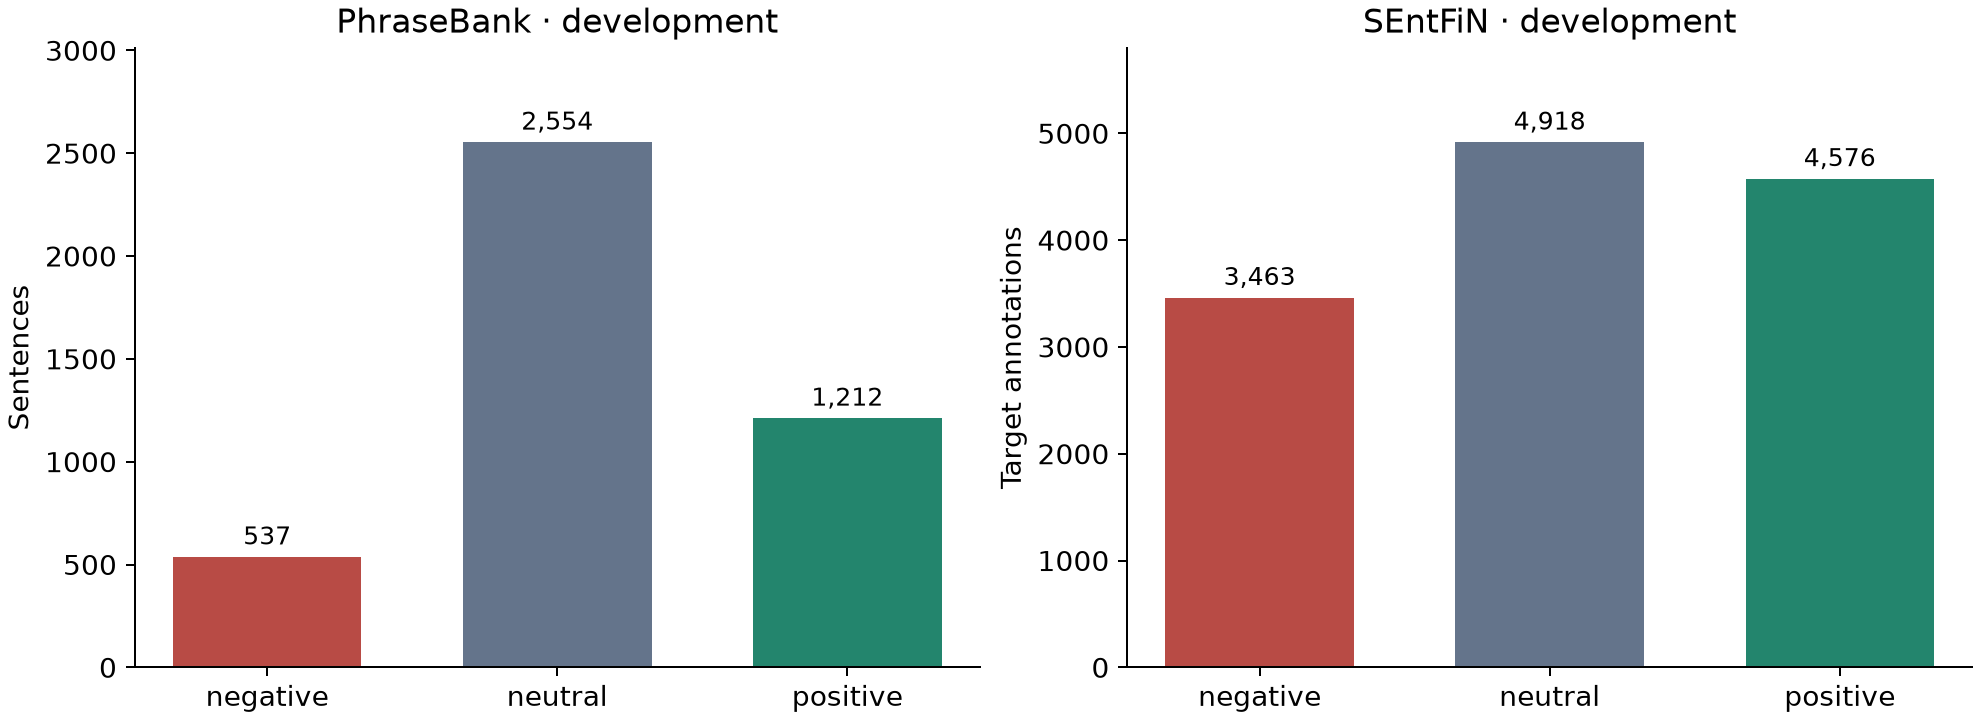

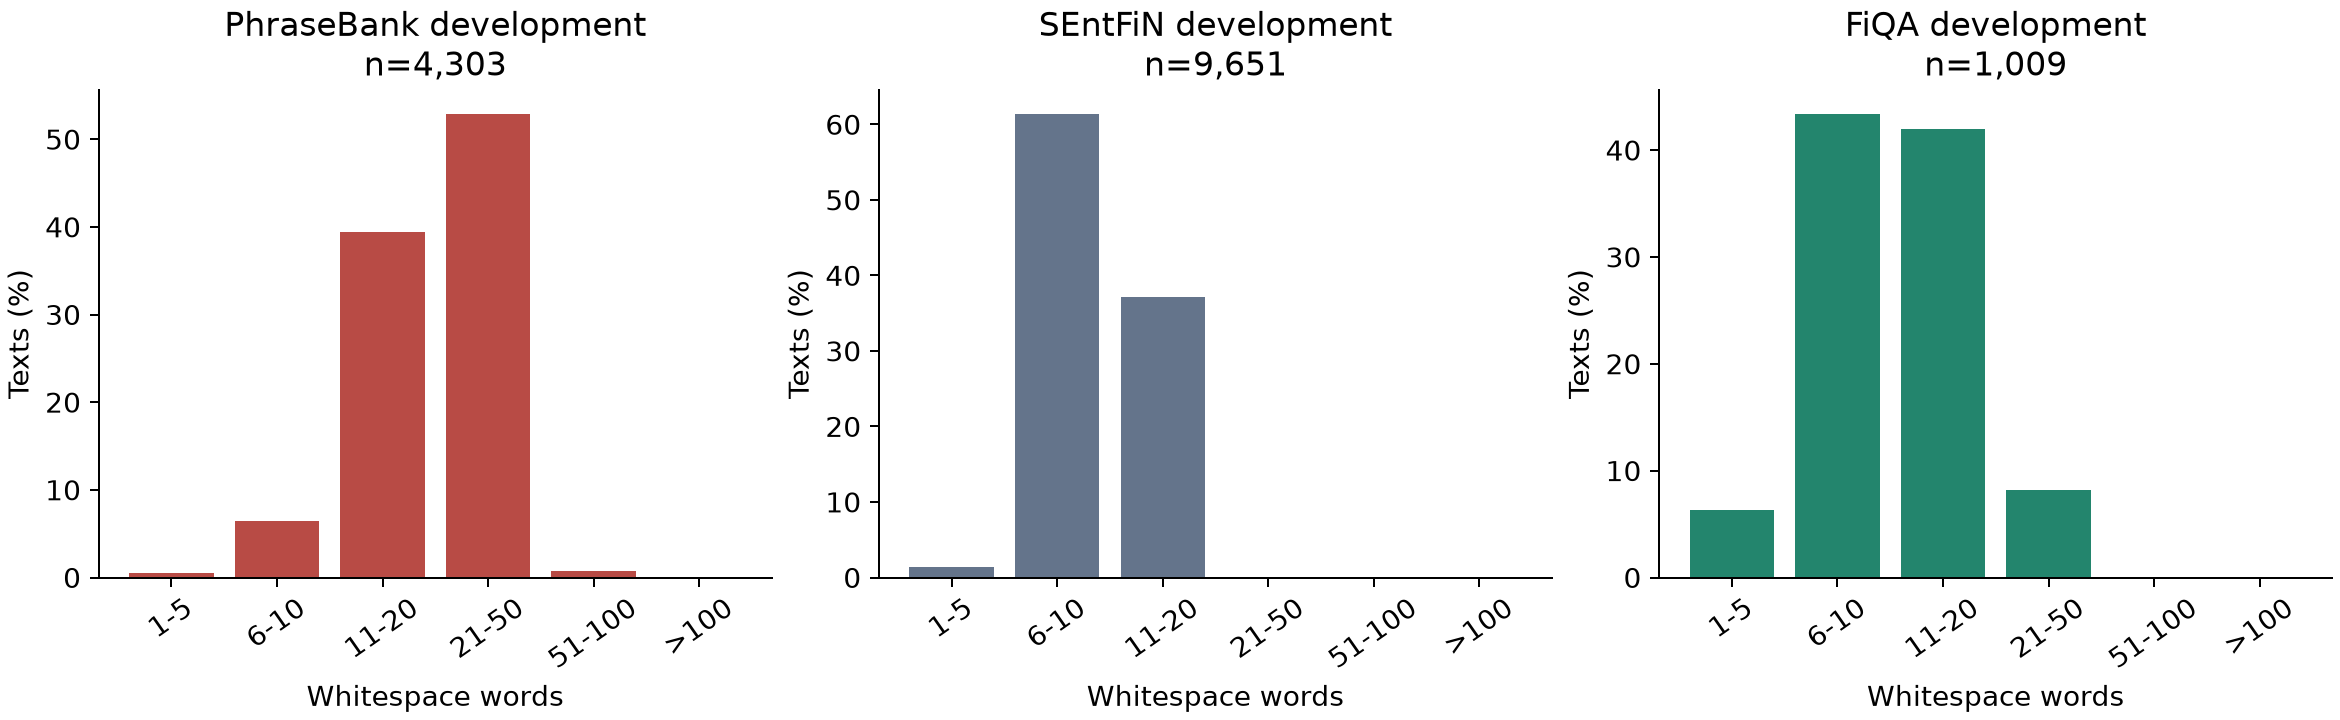

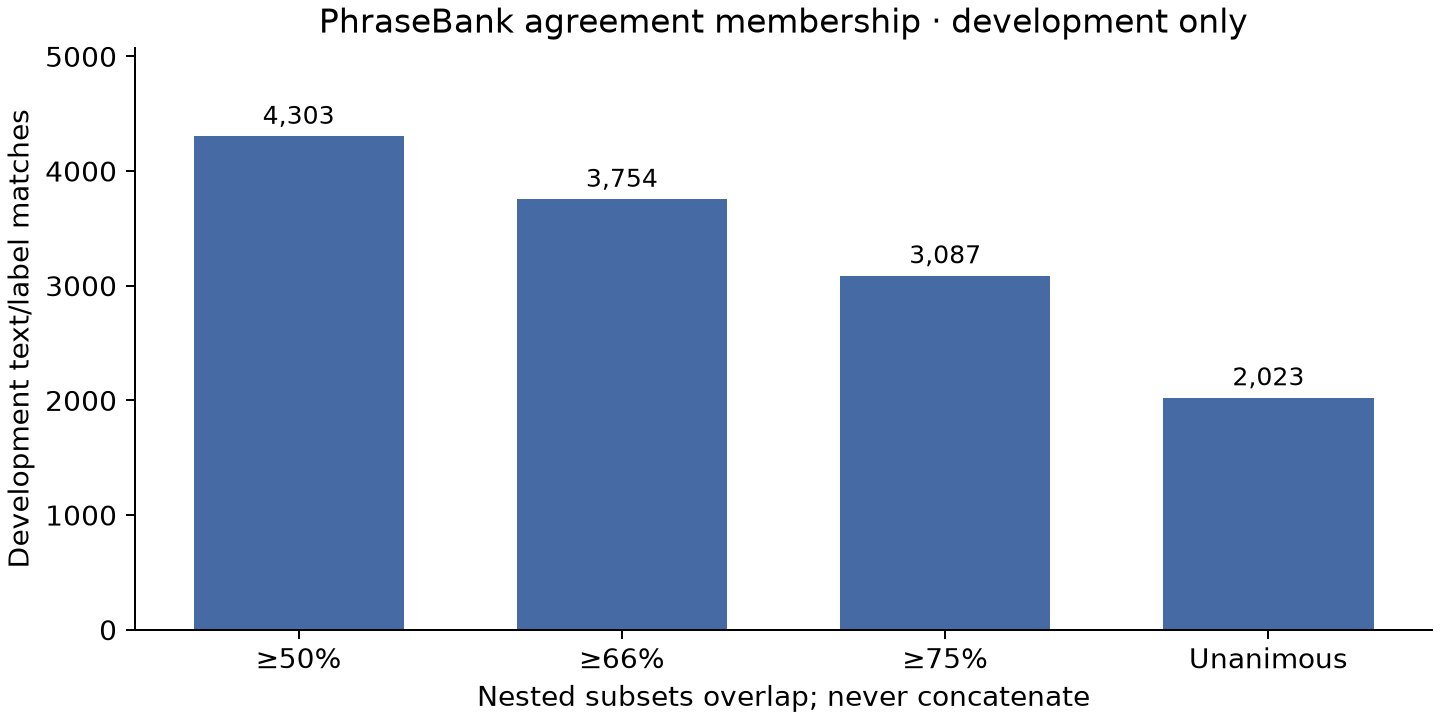

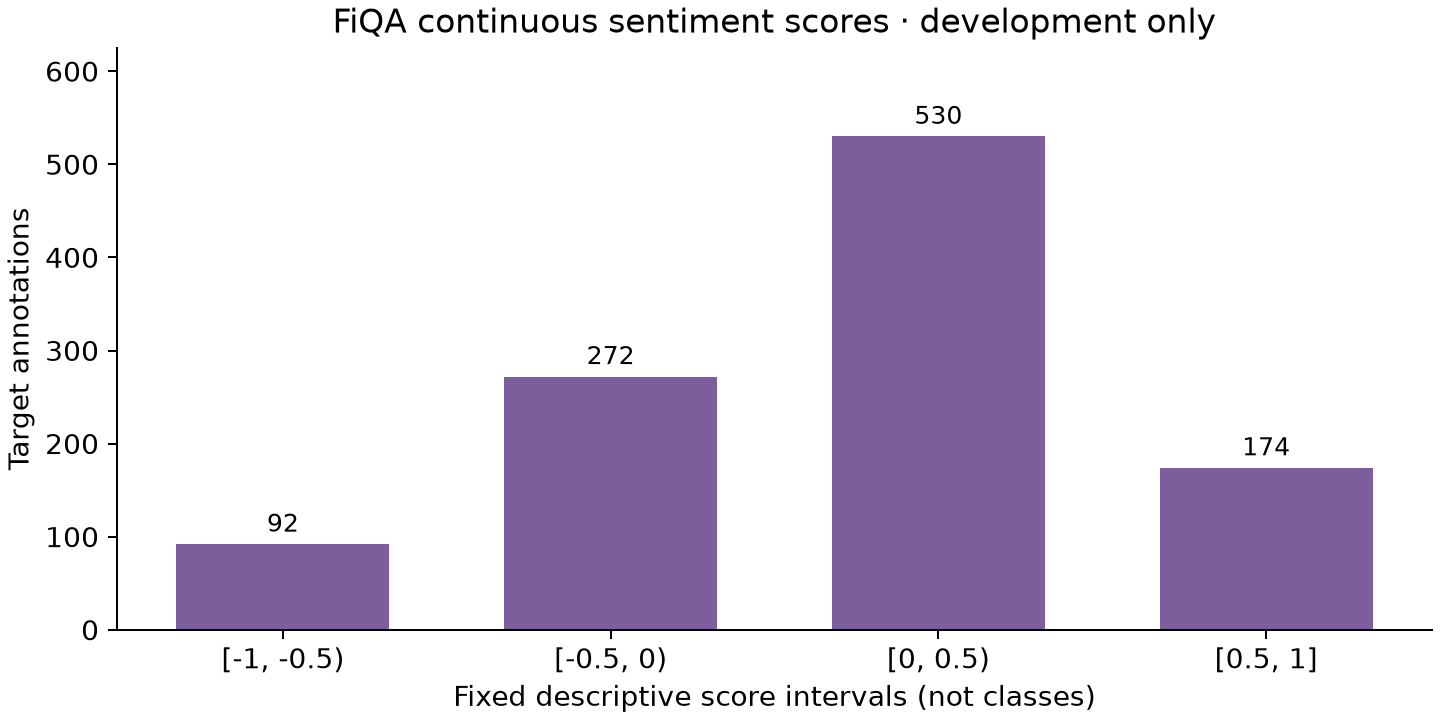

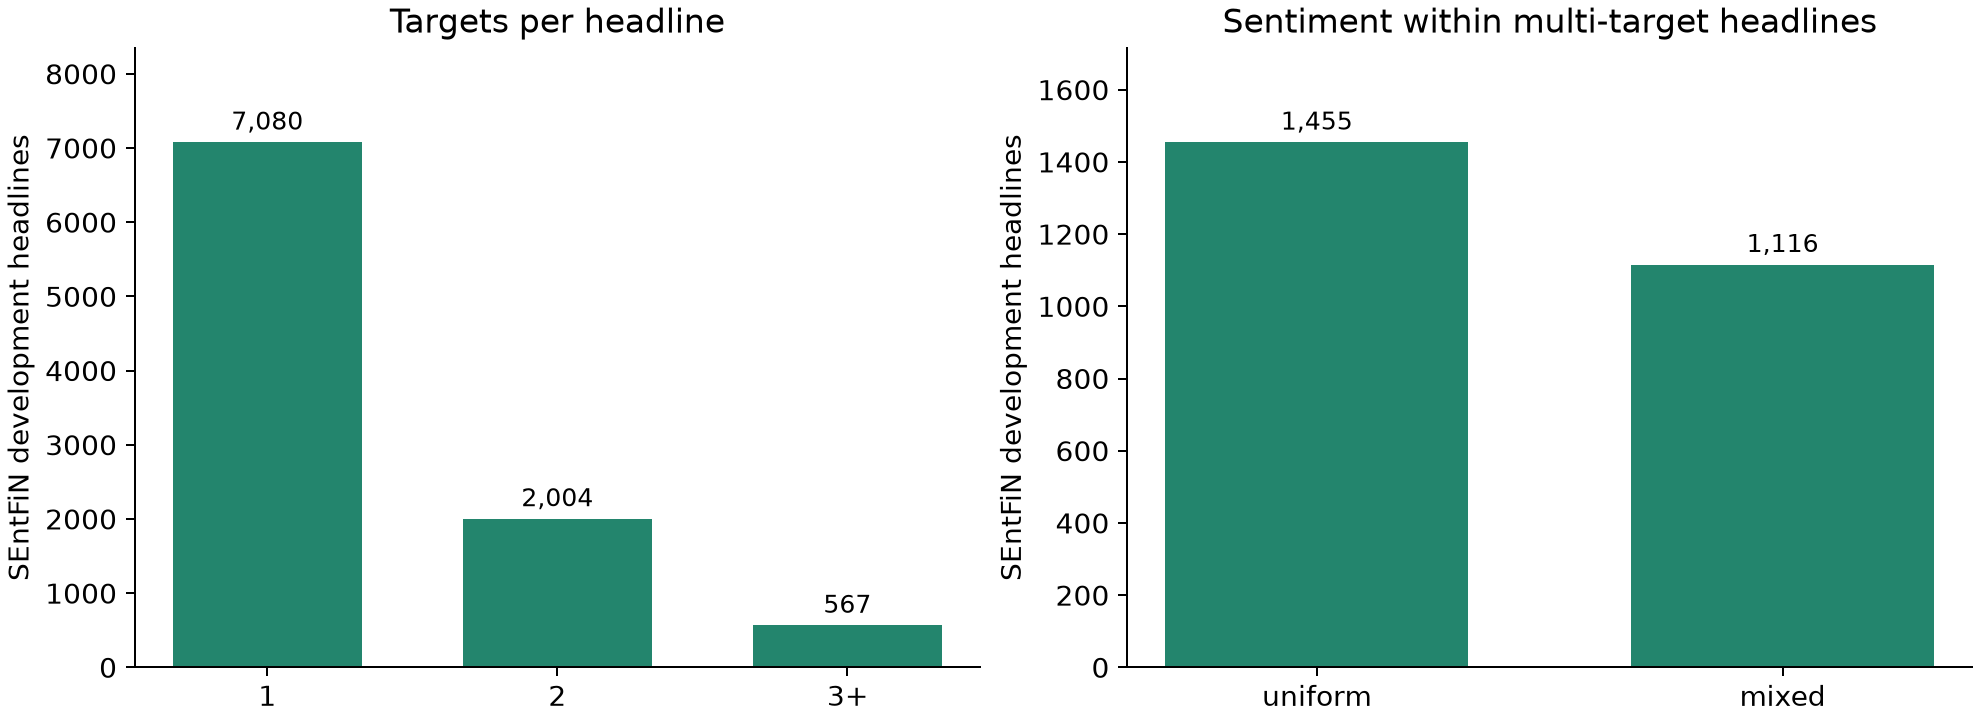

In [3]:
from IPython.display import Image, display

for name in FIGURE_NAMES:
    display(Image(filename=str(ROOT / "reports/figures/phase1" / name)))

## Interpretation and next phase

Neutral-heavy PhraseBank needs per-class reporting. Mixed SEntFiN target labels justify keeping targets together and evaluating target-aware methods separately from broadcast baselines. FiQA requires an explicit development-only decision before any three-class conversion. Full checkpoint pretraining exposure, source rights, and five-company coverage remain limited. Phase 2 begins only when separately requested; use training/validation for fitting and selection, and reserve the frozen benchmark for the locked final comparison.